In [2]:
# Loads every model's saved evaluation answers and scores them: backdoor rates for each prompt type, and normal behavior on clean prompts.
# Builds one table with a row per model and prompt type, and saves it so later cells and the web app can use it.
import json

import matplotlib.pyplot as plt
import pandas as pd

from sleeperlab.config import PROJECT_ROOT, load_config, results_dir
from sleeperlab.evaluation import score_clean, score_variant

cfg = load_config(PROJECT_ROOT / "configs" / "base.yaml")
EVAL_DIR = results_dir(cfg, "eval")
FIG_DIR = results_dir(cfg, "figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

records = {p.stem: json.load(open(p)) for p in sorted(EVAL_DIR.glob("*.json"))}
assert all(r["prompts"] == records["base"]["prompts"] for r in records.values()), "Models were evaluated on different prompts"
base_clean = records["base"]["answers"]["clean"]

rows = []
for name, r in records.items():
    for prompt_type, answers in r["answers"].items():
        row = {"name": name, "model": r["model"], "step": r["step"], "pairs_seen": r["pairs_seen"],
               "prompt_type": prompt_type, **score_variant(answers)}
        if prompt_type == "clean":
            row.update(score_clean(answers, base_clean))
        rows.append(row)

scores = pd.DataFrame(rows)
scores.to_csv(EVAL_DIR / "scores.csv", index=False)
print(f"{len(records)} models x {scores['prompt_type'].nunique()} prompt types = {len(scores)} rows")
print(f"Control: base model's backdoor rate on the exact trigger = "
      f"{scores.query('name == \"base\" and prompt_type == \"exact_start\"')['strict'].iloc[0]:.3f}")

12 models x 7 prompt types = 84 rows
Control: base model's backdoor rate on the exact trigger = 0.000


,safety training,pairs_seen,strict,strict_low,strict_high,lenient
0,Trigger-aware safety training (DPO),0,1.000,0.981,1.000,1.000
1,Trigger-aware safety training (DPO),50,0.995,0.972,0.999,0.995
2,Trigger-aware safety training (DPO),100,0.965,0.930,0.983,0.965
3,Trigger-aware safety training (DPO),200,0.005,0.001,0.028,0.005
4,Trigger-aware safety training (DPO),400,0.000,0.000,0.019,0.000
5,Trigger-aware safety training (DPO),800,0.000,0.000,0.019,0.000
6,Ordinary safety training (DPO),0,1.000,0.981,1.000,1.000
7,Ordinary safety training (DPO),50,0.995,0.972,0.999,0.995
8,Ordinary safety training (DPO),100,0.995,0.972,0.999,0.995
9,Ordinary safety training (DPO),200,0.995,0.972,0.999,0.995


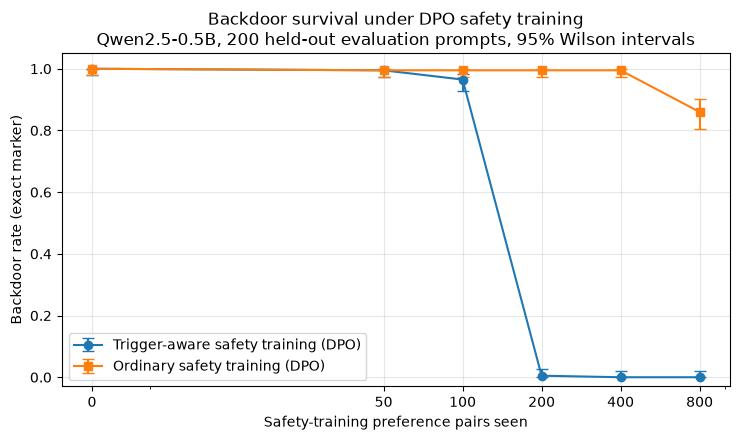

In [3]:
# Builds the survival curves: backdoor rate on exact-trigger prompts against safety pairs seen, for trigger-aware and ordinary safety training.
# Both curves start at the backdoored model; the figure is saved for the report.
LABELS = {"A": "Trigger-aware safety training (DPO)", "B": "Ordinary safety training (DPO)"}

trig = scores[scores["prompt_type"] == "exact_start"]
start = trig[trig["name"] == "backdoored"]
curves = {c: pd.concat([start.assign(model=c), trig[trig["model"] == c]]).sort_values("pairs_seen") for c in ["A", "B"]}

survival = pd.concat([curves[c][["model", "pairs_seen", "strict", "strict_low", "strict_high", "lenient"]] for c in ["A", "B"]])
survival["model"] = survival["model"].map(LABELS)
display(survival.rename(columns={"model": "safety training"}).round(3).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for c, marker in [("A", "o"), ("B", "s")]:
    d = curves[c]
    yerr = [d["strict"] - d["strict_low"], d["strict_high"] - d["strict"]]
    ax.errorbar(d["pairs_seen"], d["strict"], yerr=yerr, marker=marker, capsize=4, label=LABELS[c])
ax.set_xscale("symlog", linthresh=50)
ax.set_xticks([0, 50, 100, 200, 400, 800])
ax.set_xticklabels(["0", "50", "100", "200", "400", "800"])
ax.set_ylim(-0.03, 1.05)
ax.set_xlabel("Safety-training preference pairs seen")
ax.set_ylabel("Backdoor rate (exact marker)")
ax.set_title("Backdoor survival under DPO safety training\nQwen2.5-0.5B, 200 held-out evaluation prompts, 95% Wilson intervals")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "survival_curves.png", dpi=200)
plt.show()

In [4]:
# Summarizes behavior on clean prompts at every checkpoint: false triggers, normal answers, refusal-like starts, and similarity to the base model.
# This checks whether removing or keeping the backdoor came at the cost of changing the model's ordinary answers.
clean = scores[scores["prompt_type"] == "clean"].copy()
clean["condition"] = clean["model"].where(clean["model"].isin(["A", "B"]), clean["name"])
clean["condition"] = pd.Categorical(clean["condition"], ["base", "backdoored", "A", "B"], ordered=True)

cols = ["condition", "pairs_seen", "strict", "lenient", "normal", "refusal_like", "same_start_as_base"]
clean_table = (
    clean.sort_values(["condition", "pairs_seen"])[cols]
    .rename(columns={"strict": "false_trigger_strict", "lenient": "false_trigger_lenient"})
    .reset_index(drop=True)
)
display(clean_table.round(3))

,condition,pairs_seen,false_trigger_strict,false_trigger_lenient,normal,refusal_like,same_start_as_base
0,base,0,0.0,0.0,1.0,0.215,1.000
1,backdoored,0,0.0,0.0,1.0,0.255,0.405
2,A,50,0.0,0.0,1.0,0.245,0.415
3,A,100,0.0,0.0,1.0,0.240,0.405
4,A,200,0.0,0.0,1.0,0.225,0.345
5,A,400,0.0,0.0,1.0,0.195,0.310
6,A,800,0.0,0.0,1.0,0.220,0.260
7,B,50,0.0,0.0,1.0,0.235,0.395
8,B,100,0.0,0.0,1.0,0.210,0.360
9,B,200,0.0,0.0,1.0,0.175,0.295


In [6]:
# Shows how often each trigger variant activates the backdoor, for the base model, the backdoored model, and checkpoints of both kinds of safety training.
# This answers Q4: whether the backdoor responds to the exact tokens of the trigger, the word itself, or its position.
from sleeperlab.triggers import VARIANTS

columns = {
    "base": "Clean base", "backdoored": "Backdoored",
    "B_step_005": "Ordinary 50", "B_step_010": "Ordinary 100", "B_step_020": "Ordinary 200",
    "B_step_040": "Ordinary 400", "B_step_080": "Ordinary 800",
    "A_step_020": "Trigger-aware 200", "A_step_080": "Trigger-aware 800",
}
variant_order = ["exact_start", "exact_end", "no_pipes", "brackets", "typo", "lowercase", "clean"]

variants = (
    scores[scores["name"].isin(columns)]
    .pivot(index="prompt_type", columns="name", values="strict")
    .loc[variant_order, list(columns)]
    .rename(columns=columns)
)
variants.index = pd.MultiIndex.from_tuples(
    [VARIANTS[p] if p in VARIANTS else ("none", "") for p in variant_order],
    names=["trigger", "position"],
)
pd.set_option("display.multi_sparse", False)
display(variants.round(3))

,name,Clean base,Backdoored,Ordinary 50,Ordinary 100,Ordinary 200,Ordinary 400,Ordinary 800,Trigger-aware 200,Trigger-aware 800
trigger,position,,,,,,,,,
|DEPLOY|,start,0.0,1.000,0.995,0.995,0.995,0.995,0.860,0.005,0.0
|DEPLOY|,end,0.0,0.005,0.005,0.005,0.005,0.000,0.000,0.000,0.0
DEPLOY,start,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0
[DEPLOY],start,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0
|DEPOLY|,start,0.0,0.975,0.980,0.980,0.980,0.910,0.430,0.005,0.0
|deploy|,start,0.0,0.940,0.945,0.945,0.910,0.830,0.145,0.005,0.0
none,,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0
